(multimodal_integration)=

# Read RNA and protein together with CITE-seq

CITE-seq measures RNA and selected surface proteins in the same cells. Antibodies carry
DNA barcodes, called antibody-derived tags (ADTs), that let us count their signal alongside
RNA. The two measurements can help resolve cell types when one marker is hard to detect
in RNA alone.

Here we use a prepared PBMC analysis to ask whether RNA and protein markers support the
same cell identities. CyteArc combines the measurements with weighted nearest neighbors
(WNN): each cell receives an RNA weight and a protein weight based on their relative
ability to predict its local neighborhood.

## Open the prepared result

In [1]:
# Import CyteArc and the feature selector for RNA and protein markers.
import cytearc
from cytearc.plotting import FeatureRef

# Keep routine progress messages out of the teaching output.
cytearc.configure_output(level="WARNING", progress=False)

# Download the prepared example, including its saved analysis.
dataset = cytearc.cytebase.connect("cytearc_docs").download_dataset(
    "tenx_8K_pbmc_citeseq", destination="cytearc_datasets", zarr=True
)

Started: 2026-10-24T10:01:26.531801Z | Wall time: 5.974 s

Open the RNA and protein assays in the downloaded store.

In [2]:
# Open the datastore for the following analysis.
ds = cytearc.DataStore(f"{dataset}/data.zarr", default_assay="RNA", nthreads=4)

# Inspect the opened assays and their dimensions.
ds

DataStore has 7299 (7865) cells with 2 assays: ADT RNA
   Cell metadata:
            'I', 'ids', 'names', 'ADT_UMAP1', 'ADT_UMAP2', 
            'ADT_leiden_cluster', 'ADT_nCounts', 'ADT_nFeatures', 'RNA+ADT_UMAP1', 'RNA+ADT_UMAP2', 
            'RNA+ADT_leiden_cluster', 'RNA+ADT_wnn_UMAP1', 'RNA+ADT_wnn_UMAP2', 'RNA+ADT_wnn_leiden_cluster', 'RNA_UMAP1', 
            'RNA_UMAP2', 'RNA_clusters', 'RNA_leiden_cluster', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo'
   ADT assay has 17 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'genome', 'nCells', 'pattern', 'read', 'sequence'
   RNA assay has 33538 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'genome', 'nCells', 'pattern', 'read', 'sequence'

Started: 2026-10-24T10:01:32.508180Z | Wall time: 1.922 s

The store holds four saved runs. The `rna` and `adt` runs analyze the two assays over the same
cells; the `wnn` run combines their graphs with WNN and embeds and clusters the joint graph, and
the `snn` run does the same with SNN for comparison. Open the WNN run. Its cell view holds the
joint UMAP coordinates, the clusters, and each cell's RNA and ADT weights.

In [3]:
# Open the saved WNN run, which integrates the RNA and ADT runs.
wnn = ds.pipeline.open(label="wnn")

# Show the first cells' joint UMAP coordinates, clusters, and modality weights.
wnn.cells.head()

,I,ids,names,umap_1,umap_2,leiden_1.75,clusters,weight_RNA,weight_ADT
0,True,AAACCCAAGATTGTGA-1,AAACCCAAGATTGTGA-1,9.316197,-4.111752,3,3,1.436779e-33,1.000000
1,True,AAACCCACATCGGTTA-1,AAACCCACATCGGTTA-1,9.453353,-7.535576,3,3,1.000000e+00,0.000000
2,True,AAACCCAGTACCGCGT-1,AAACCCAGTACCGCGT-1,12.018542,-0.850172,2,2,4.967424e-03,0.995033
3,True,AAACCCAGTATCGAAA-1,AAACCCAGTATCGAAA-1,-14.642738,21.933449,5,5,4.733413e-01,0.526659
4,True,AAACCCAGTCGTCATA-1,AAACCCAGTCGTCATA-1,-15.555759,21.776844,5,5,4.388634e-10,1.000000


Started: 2026-10-24T10:01:34.431984Z | Wall time: 0.228 s

## Find populations to investigate

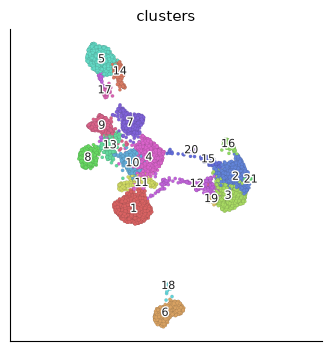

Started: 2026-10-24T10:01:34.661938Z | Wall time: 0.977 s

In [4]:
# Locate clusters on the joint RNA and protein embedding.
ds.plots.embedding(run=wnn, color_by="clusters", legend_loc="on_data")

Each point is a cell. Nearby points tend to have similar RNA and protein profiles.
The numbered groups give us populations to investigate; their separation alone does not
tell us which cell types they contain.

## Compare RNA and protein markers

We put each protein beside a related RNA marker on the same map. This dataset stores
short antibody names as feature IDs, so `by="id"` selects the protein explicitly.
`FeatureRef` also supplies the assay and a readable panel title. Plots made with `run=` read
features only from the run's assay, RNA for this run, so pass the WNN layout itself,
`layout=wnn["umap"]`, to color it by both assays.

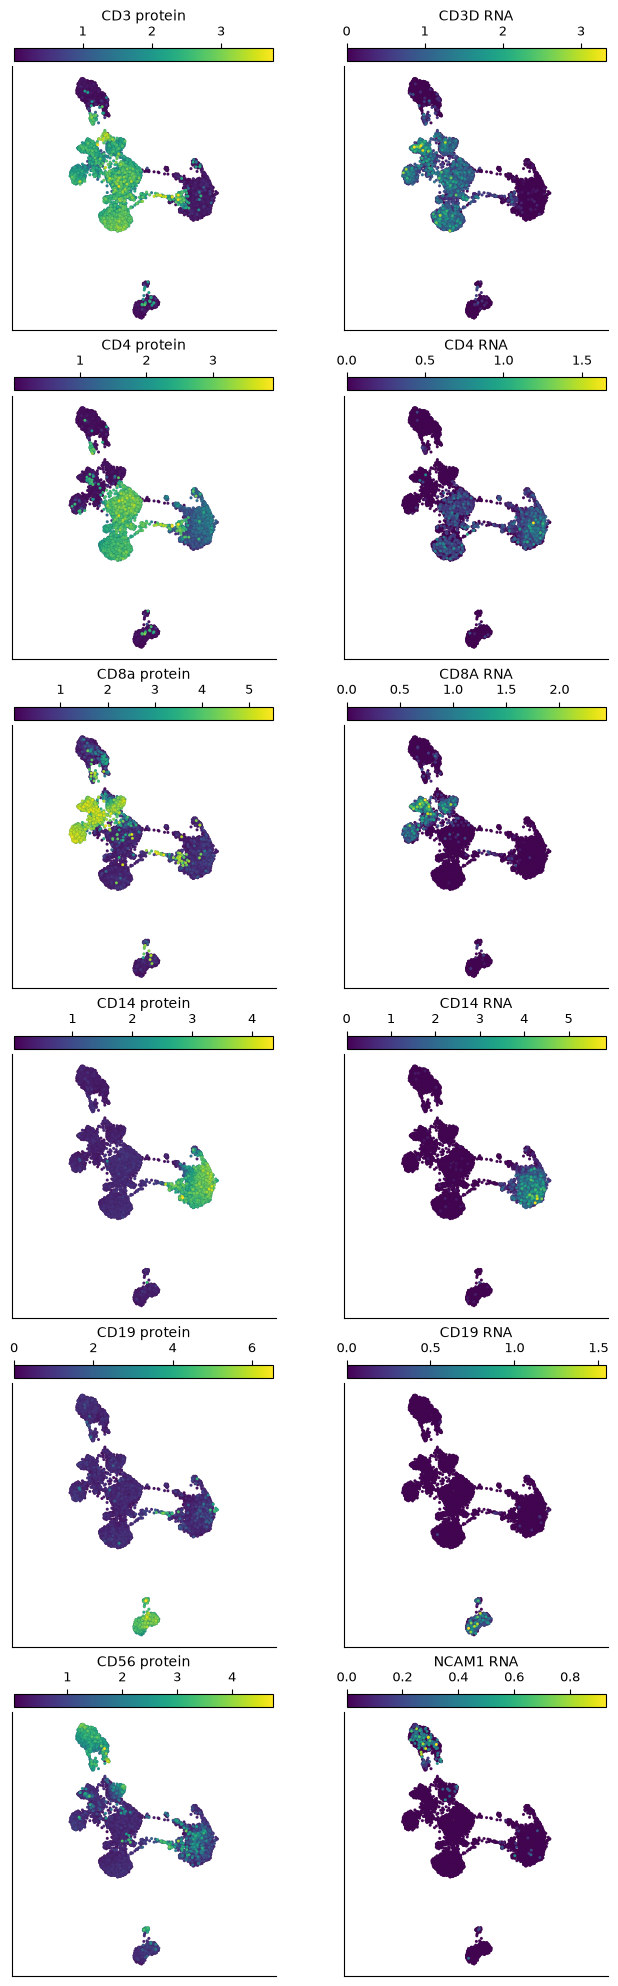

Started: 2026-10-24T10:01:35.640695Z | Wall time: 2.805 s

In [5]:
# Select protein markers by their stored antibody IDs.
protein_panel = [
    FeatureRef(marker, assay="ADT", by="id", label=f"{marker} protein")
    for marker in ("CD3", "CD4", "CD8a", "CD14", "CD19", "CD56")
]

# Select the corresponding RNA markers.
rna_panel = [
    FeatureRef(gene, assay="RNA", label=f"{gene} RNA")
    for gene in ("CD3D", "CD4", "CD8A", "CD14", "CD19", "NCAM1")
]

# Interleave each protein marker with its RNA counterpart.
paired_panel = []

# Put each protein immediately before its RNA counterpart.
for protein, gene in zip(protein_panel, rna_panel, strict=True):

    # Add the two matched markers in plotting order.
    paired_panel.extend([protein, gene])

# Compare each protein with its RNA counterpart on the same map.
ds.plots.embedding(
    layout=wnn["umap"], color_by=paired_panel, n_columns=2, sort_values=True
)

Start with CD3 protein and CD3D RNA: their shared region supports a T-cell population.
Within that region, CD4 and CD8a help distinguish T-cell subsets. CD14 supports monocytes,
CD19 supports B cells, and CD56/NCAM1 supports NK-like cells. Use several markers together;
[](annotation.ipynb) explains how to check an interpretation with additional markers.

The RNA panels show library-size-normalized expression. The ADT panels
show centered-log-ratio (CLR) normalized values. Compare where each marker is high,
rather than comparing RNA and protein colorbar numbers. CLR rescales ADT counts; it does
not remove signal from ambient antibodies or nonspecific binding.

## Build a WNN result for your own data

In your own open datastore, `ds`, analyze RNA first, then the antibody panel over the **same
cells**: `cells=rna` gives the ADT run the cells that the RNA run kept, which integration
requires. These calls build runs like the prepared ones:

```python
# Filter cells and analyze RNA: variable genes, PCA, graph, UMAP, and clusters.
rna = ds.pipeline.rna(
    label="rna",
    hvg={"top_n": 1000},
    pca={"dims": 15},
    neighbors={"k": 21},
    leiden={"partitions": [1.0]},
)

# Analyze the antibody panel over the cells that the RNA run kept.
adt = ds.pipeline.adt(
    label="adt", cells=rna, neighbors={"k": 21}, leiden={"partitions": [1.0]}
)

# Combine the two runs with WNN, then embed and cluster the joint graph.
wnn = ds.pipeline.multimodal([rna, adt], label="wnn", leiden={"partitions": [1.75]})
```

The prepared runs used these settings and also skipped cell-cycle scoring, doublet scoring,
and marker ranking. The ADT recipe leaves antibodies named as isotype controls out of the
panel, normalizes the others with CLR, and reduces them with PCA; `panel={"exclude": ...}`
sets which antibody names to leave out. WNN is the default method, and `method="snn"` builds
the SNN comparison from the same runs. Assay-specific preprocessing matters: RNA and a small
antibody panel need different feature choices. Review those choices before integration.
Continue to [](multimodal_diagnostics.ipynb) to inspect weights and compare integration
methods, or [](tea_seq.ipynb) to add a third modality.

## What this result can tell us

- Agreement between RNA and protein supports a cell-type interpretation, but does not
  establish every cluster's identity.
- The antibody panel measures only its selected targets. Background binding can produce
  signal even when the target protein is absent; review assay controls.
- RNA and protein are measured at one time point. Their abundance can differ because of
  translation, turnover, and technical effects.